# Proyek Analisis Data: Air Quality Dataset in Changping, Beijing
- **Nama:** Melvan Safero Lee
- **Email:** melvansafero@gmail.com
- **ID Dicoding:** melvanslee2505

# Menentukan Pertanyaan Bisnis

**Pertanyaan Utama**

"Bagaimana karakteristik konsentrasi PM2.5 berdasarkan pola temporal, hubungan dengan variabel meteorologi, dan keterkaitannya dengan polutan lain di stasiun pemantauan Changping, Beijing, selama periode Maret 2013 hingga Februari 2017, serta bagaimana hasil analisis tersebut dapat mendukung penentuan prioritas pemantauan kualitas udara?"

**Keterangan (Prinsip SMART):**

- **Specific:** Berfokus pada karakteristik konsentrasi PM2.5 di stasiun Changping, Beijing, berdasarkan pola temporal, variabel meteorologi, dan polutan lainnya.
- **Measurable:** Menggunakan rata-rata konsentrasi PM2.5, distribusi konsentrasi berdasarkan waktu, serta koefisien korelasi antarvariabel.
- **Action-Oriented:** Hasil analisis dapat membantu mengidentifikasi periode dengan konsentrasi PM2.5 tinggi serta variabel yang memiliki hubungan kuat dengan PM2.5 sebagai bahan pertimbangan dalam menentukan prioritas pemantauan kualitas udara.
- **Relevant:** Analisis mendukung pemahaman terhadap karakteristik pencemaran udara dan pemantauan kualitas lingkungan.
- **Time-bound:** Analisis dibatasi pada periode Maret 2013 hingga Februari 2017.

**Pertanyaan Turunan:**

1. **Pertanyaan 1:** Bagaimana pola perubahan rata-rata konsentrasi PM2.5 berdasarkan jam dan bulan selama periode Maret 2013 hingga Februari 2017?

2. **Pertanyaan 2:** Bagaimana arah dan kekuatan hubungan antara konsentrasi PM2.5 dan variabel meteorologi, meliputi suhu, tekanan udara, curah hujan, kelembapan titik embun, serta kecepatan angin, selama periode Maret 2013 hingga Februari 2017?

3. **Pertanyaan 3:** Polutan apa yang memiliki hubungan paling kuat dengan konsentrasi PM2.5 berdasarkan koefisien korelasi Spearman selama periode Maret 2013 hingga Februari 2017?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load DataFrame

In [2]:
file_path = Path("/Users/melvankerja/Desktop/Proyek_Analisis_Data/PRSA_Data_Changping_20130301-20170228.csv")
df = pd.read_csv(file_path)
print("Ukuran dataset:", df.shape)
display(df.head())
display(df.info())

Ukuran dataset: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,3.00,6.00,13.00,7.00,300.00,85.00,-2.30,1020.80,-19.70,0.00,E,0.50,Changping
1,2,2013,3,1,1,3.00,3.00,6.00,6.00,300.00,85.00,-2.50,1021.30,-19.00,0.00,ENE,0.70,Changping
2,3,2013,3,1,2,3.00,3.00,22.00,13.00,400.00,74.00,-3.00,1021.30,-19.90,0.00,ENE,0.20,Changping
3,4,2013,3,1,3,3.00,6.00,12.00,8.00,300.00,81.00,-3.60,1021.80,-19.10,0.00,NNE,1.00,Changping
4,5,2013,3,1,4,3.00,3.00,14.00,8.00,300.00,81.00,-3.50,1022.30,-19.40,0.00,N,2.10,Changping


<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34290 non-null  float64
 6   PM10     34482 non-null  float64
 7   SO2      34436 non-null  float64
 8   NO2      34397 non-null  float64
 9   CO       33543 non-null  float64
 10  O3       34460 non-null  float64
 11  TEMP     35011 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34924 non-null  str    
 16  WSPM     35021 non-null  float64
 17  station  35064 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 5.2 MB


None

**Insight:** 
- Dataset PRSA Data Changping memiliki 35.064 baris dan 18 kolom, yang mencakup informasi waktu, konsentrasi polutan udara, kondisi meteorologi, dan identitas stasiun pemantauan.

- Dataset mencatat pengamatan per jam dari Maret 2013 hingga Februari 2017. Kolom year, month, day, dan hour dapat digunakan untuk membentuk variabel waktu (datetime) agar analisis tren temporal dapat dilakukan.

- Dataset memiliki 11 kolom numerik bertipe float64, 5 kolom bertipe int64, dan 2 kolom bertipe string (wd dan station).

- Variabel PM2.5 dipilih sebagai fokus utama analisis karena merepresentasikan konsentrasi partikel halus di udara. Variabel polutan lainnya dan kondisi meteorologi dapat digunakan untuk mengeksplorasi pola yang berhubungan dengan perubahan konsentrasi PM2.5.

- Berdasarkan jumlah nilai non-null, beberapa kolom memiliki missing values, terutama CO (33.543 nilai valid), NO2 (34.397), dan SO2 (34.436). Oleh karena itu, diperlukan pemeriksaan kualitas data lebih lanjut sebelum melakukan analisis.

### Assessing Data - Identifying Problems

In [3]:
# 1. Struktur dataset
print("Jumlah baris dan kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)

# 2. Missing values
missing = df.isna().sum()
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (missing / len(df) * 100).round(2)
})
display(missing_summary[missing_summary["missing_count"] > 0])

# 3. Duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

# 4. Duplikasi observasi berdasarkan waktu
print(
    "Duplikasi kombinasi waktu:",
    df.duplicated(subset=["year", "month", "day", "hour"]).sum()
)

# 5. Statistik deskriptif
display(df.describe(include="all").T)

# 6. Pemeriksaan nilai negatif pada variabel yang tidak boleh negatif
nonnegative_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "RAIN", "WSPM"
]

for col in nonnegative_cols:
    if col in df.columns:
        print(f"{col}: {(df[col] < 0).sum()} nilai negatif")

Jumlah baris dan kolom: (35064, 18)

Tipe data:
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object


,missing_count,missing_percentage
PM2.5,774,2.21
PM10,582,1.66
SO2,628,1.79
NO2,667,1.90
CO,1521,4.34
O3,604,1.72
TEMP,53,0.15
PRES,50,0.14
DEWP,53,0.15
RAIN,51,0.15


Jumlah baris duplikat: 0
Duplikasi kombinasi waktu: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No,35064.00,NaN,NaN,NaN,17532.50,10122.25,1.00,8766.75,17532.50,26298.25,35064.00
year,35064.00,NaN,NaN,NaN,2014.66,1.18,2013.00,2014.00,2015.00,2016.00,2017.00
month,35064.00,NaN,NaN,NaN,6.52,3.45,1.00,4.00,7.00,10.00,12.00
day,35064.00,NaN,NaN,NaN,15.73,8.80,1.00,8.00,16.00,23.00,31.00
hour,35064.00,NaN,NaN,NaN,11.50,6.92,0.00,5.75,11.50,17.25,23.00
PM2.5,34290.00,NaN,NaN,NaN,71.10,72.33,2.00,18.00,46.00,100.00,882.00
PM10,34482.00,NaN,NaN,NaN,94.66,83.44,2.00,34.00,72.00,131.00,999.00
SO2,34436.00,NaN,NaN,NaN,14.96,20.98,0.29,2.00,7.00,18.00,310.00
NO2,34397.00,NaN,NaN,NaN,44.18,29.52,1.85,22.00,36.00,60.36,226.00
CO,33543.00,NaN,NaN,NaN,1152.30,1103.06,100.00,500.00,800.00,1400.00,10000.00


PM2.5: 0 nilai negatif
PM10: 0 nilai negatif
SO2: 0 nilai negatif
NO2: 0 nilai negatif
CO: 0 nilai negatif
O3: 0 nilai negatif
RAIN: 0 nilai negatif
WSPM: 0 nilai negatif


**Insight:** 
- Problem 1 — Missing Values: Dataset memiliki nilai kosong pada sejumlah variabel. Kolom CO memiliki missing values terbanyak, yaitu 1.521 (4,34%), diikuti PM2.5 sebanyak 774 (2,21%), NO2 sebanyak 667 (1,90%), SO2 sebanyak 628 (1,79%), dan PM10 sebanyak 582 (1,66%). Missing values perlu ditangani agar tidak mengurangi kualitas analisis kualitas udara.

- Problem 2 — Outliers: Statistik deskriptif menunjukkan nilai maksimum yang jauh lebih tinggi daripada kuartil ketiga pada beberapa variabel, misalnya PM2.5 sebesar 882 dibandingkan Q3 sebesar 100, PM10 sebesar 999 dibandingkan Q3 sebesar 131, dan CO sebesar 10.000 dibandingkan Q3 sebesar 1.400. Kondisi ini mengindikasikan adanya nilai ekstrem yang perlu diperiksa lebih lanjut untuk membedakan lonjakan polusi yang valid dari kesalahan pencatatan.

- Hasil pemeriksaan tambahan: Tidak ditemukan baris duplikat maupun duplikasi kombinasi waktu berdasarkan output yang ditampilkan. Selain itu, tidak ditemukan nilai negatif pada variabel polutan, curah hujan, dan kecepatan angin yang diperiksa.

- Kesimpulan: Permasalahan utama yang perlu diprioritaskan pada tahap cleaning adalah penanganan missing values dan pemeriksaan outliers. Data ekstrem tidak boleh langsung dihapus karena dapat merepresentasikan kejadian pencemaran udara yang nyata.

**Steps to Take — Cleaning Data**
1. Menangani missing values dengan mempertimbangkan karakteristik setiap variabel dan urutan waktu. Interpolasi temporal dapat dipertimbangkan untuk celah pendek, sedangkan celah panjang perlu dievaluasi secara terpisah.
2. Memeriksa outliers menggunakan metode IQR dan boxplot, kemudian memvalidasi nilai ekstrem sebelum memutuskan apakah perlu dikoreksi atau dipertahankan.
3. Memeriksa kembali jumlah missing values, duplikasi, dan statistik deskriptif setelah cleaning untuk memastikan kualitas data meningkat.

### Data Cleaning — Identifying Data Quality Issues

Berdasarkan hasil data assessment, ditemukan beberapa permasalahan kualitas data yang perlu ditangani sebelum melakukan Exploratory Data Analysis (EDA).

**1. Missing Values**

Dataset memiliki missing values pada beberapa variabel, dengan jumlah tertinggi pada CO sebanyak 1.521 (4,34%), PM2.5 sebanyak 774 (2,21%), NO2 sebanyak 667 (1,90%), SO2 sebanyak 628 (1,79%), dan PM10 sebanyak 582 (1,66%).

Missing values pada variabel polutan dapat mengurangi jumlah observasi yang tersedia untuk analisis. Oleh karena itu, diperlukan metode penanganan yang mempertimbangkan karakteristik data dan urutan waktu pengamatan.

**2. Potential Outliers**

Hasil statistik deskriptif menunjukkan adanya nilai maksimum yang cukup jauh dari kuartil ketiga pada beberapa variabel. Contohnya, PM2.5 memiliki nilai maksimum 882, sedangkan Q3 sebesar 100. PM10 memiliki nilai maksimum 999 dengan Q3 sebesar 131, sementara CO mencapai 10.000 dengan Q3 sebesar 1.400.

Kondisi tersebut mengindikasikan kemungkinan adanya nilai ekstrem. Namun, nilai tersebut tidak dapat langsung dianggap sebagai kesalahan karena mungkin merepresentasikan episode pencemaran udara yang sebenarnya.

**3. Data Integrity and Consistency**

Pemeriksaan menunjukkan bahwa tidak terdapat baris duplikat maupun duplikasi kombinasi waktu berdasarkan variabel year, month, day, dan hour. Selain itu, tidak ditemukan nilai negatif pada variabel polutan, curah hujan, dan kecepatan angin yang diperiksa.

Meskipun demikian, informasi waktu masih terpisah dalam empat kolom, sehingga perlu digabungkan menjadi satu variabel datetime untuk mendukung analisis berdasarkan urutan waktu.

**Cleaning Strategy**

Berdasarkan permasalahan tersebut, strategi pembersihan data yang diterapkan meliputi:

1. Menghapus baris duplikat untuk menghindari penghitungan observasi yang sama lebih dari satu kali.
2. Membentuk variabel datetime dari year, month, day, dan hour, kemudian mengurutkan observasi berdasarkan waktu.
3. Menangani missing values numerik menggunakan time-based interpolation dengan batas maksimal tiga observasi berturut-turut. Interpolasi hanya dilakukan pada missing values yang berada di antara dua observasi valid.
4. Mempertahankan nilai ekstrem untuk sementara karena belum terdapat bukti bahwa nilai tersebut merupakan kesalahan pencatatan.

Setelah proses cleaning, dilakukan pemeriksaan ulang terhadap jumlah observasi, timestamp, dan missing values untuk mengevaluasi hasil pembersihan data.

### Cleaning Data - Fixing Problem

In [4]:
df_clean = df.copy()

# Hapus baris yang identik sepenuhnya
df_clean = df_clean.drop_duplicates()

# Buat timestamp
df_clean["datetime"] = pd.to_datetime(
    df_clean[["year", "month", "day", "hour"]],
    errors="coerce"
)

# Hapus timestamp yang tidak valid
df_clean = df_clean.dropna(subset=["datetime"])

# Urutkan berdasarkan waktu
df_clean = df_clean.sort_values("datetime")

# Periksa timestamp duplikat
duplicate_time = df_clean["datetime"].duplicated().sum()
print("Timestamp duplikat setelah pembersihan:", duplicate_time)

# Karena dataset ini untuk satu stasiun, periksa sebelum menghapus
# observasi dengan timestamp yang sama.
if duplicate_time > 0:
    print("Perlu investigasi timestamp duplikat sebelum menentukan tindakan.")

# Interpolasi hanya untuk missing values numerik yang berada
# di antara dua pengamatan valid; jangan mengisi semua kolom secara buta.
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

df_clean = df_clean.set_index("datetime")

df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

df_clean = df_clean.reset_index()

print("Ukuran sebelum cleaning:", df.shape)
print("Ukuran setelah cleaning:", df_clean.shape)
print("Sisa missing values:", df_clean.isna().sum().sum())

display(df_clean.head())

Timestamp duplikat setelah pembersihan: 0
Ukuran sebelum cleaning: (35064, 18)
Ukuran setelah cleaning: (35064, 19)
Sisa missing values: 2590


,datetime,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,1,2013,3,1,0,3.00,6.00,13.00,7.00,300.00,85.00,-2.30,1020.80,-19.70,0.00,E,0.50,Changping
1,2013-03-01 01:00:00,2,2013,3,1,1,3.00,3.00,6.00,6.00,300.00,85.00,-2.50,1021.30,-19.00,0.00,ENE,0.70,Changping
2,2013-03-01 02:00:00,3,2013,3,1,2,3.00,3.00,22.00,13.00,400.00,74.00,-3.00,1021.30,-19.90,0.00,ENE,0.20,Changping
3,2013-03-01 03:00:00,4,2013,3,1,3,3.00,6.00,12.00,8.00,300.00,81.00,-3.60,1021.80,-19.10,0.00,NNE,1.00,Changping
4,2013-03-01 04:00:00,5,2013,3,1,4,3.00,3.00,14.00,8.00,300.00,81.00,-3.50,1022.30,-19.40,0.00,N,2.10,Changping


**Insight:** 
- Timestamp berhasil dibuat: Kolom datetime berhasil menggabungkan informasi year, month, day, dan hour. Dataset sekarang memiliki 19 kolom, bertambah satu kolom dari dataset awal.

- Tidak ada timestamp duplikat: Hasil pemeriksaan menunjukkan 0 timestamp duplikat, sehingga tidak diperlukan penghapusan observasi berdasarkan duplikasi waktu.

- Jumlah observasi dipertahankan: Dataset tetap memiliki 35.064 baris setelah proses cleaning. Tidak ada baris yang hilang akibat proses tersebut.

- Missing values masih tersisa: Terdapat 2.590 nilai kosong setelah interpolasi. Hal ini menunjukkan bahwa sebagian missing values belum dapat ditangani, sehingga perlu diperiksa kembali berdasarkan variabel dan pola waktu.

- Kesimpulan: Struktur waktu dataset sudah siap untuk analisis temporal, tetapi penanganan missing values perlu dievaluasi sebelum hasil EDA diinterpretasikan.

### Cleaning Data — Results and Evaluation

Berdasarkan proses pembersihan data yang telah dilakukan, diperoleh beberapa hasil sebagai berikut:

- **Timestamp creation:** Kolom year, month, day, dan hour berhasil digabungkan menjadi variabel datetime. Dataset kini memiliki 19 kolom.
- **Duplicate removal:** Tidak ditemukan baris duplikat maupun timestamp duplikat. Dengan demikian, tidak ada observasi yang perlu dihapus karena duplikasi.
- **Temporal interpolation:** Interpolasi berbasis waktu berhasil menangani sebagian missing values numerik, dengan batas maksimal tiga observasi berturut-turut dan hanya pada bagian internal deret waktu.
- **Observation preservation:** Jumlah observasi tetap sebanyak 35.064 baris. Tidak ada baris yang dihapus selama proses cleaning.
- **Remaining missing values:** Masih terdapat 2.590 missing values setelah interpolasi. Nilai yang tersisa dapat berasal dari celah yang lebih panjang dari batas interpolasi maupun missing values pada bagian awal atau akhir deret waktu. Missing values pada variabel kategorikal juga belum ditangani.

**Conclusion:**

Proses cleaning berhasil memperbaiki struktur temporal dataset dan menangani sebagian missing values tanpa mengurangi jumlah observasi. Namun, dataset belum sepenuhnya bebas dari missing values. Oleh karena itu, analisis selanjutnya perlu mempertimbangkan ketersediaan data pada masing-masing variabel agar hasil analisis tidak bias akibat penanganan missing values yang tidak tepat.

### Mengecek Outlier dan Plot Boxplot

In [5]:
outlier_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3"
]

for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    print(f"{col}: {count} potential outliers")

PM2.5: 1698 potential outliers
PM10: 1337 potential outliers
SO2: 3176 potential outliers
NO2: 809 potential outliers
CO: 2657 potential outliers
O3: 1627 potential outliers


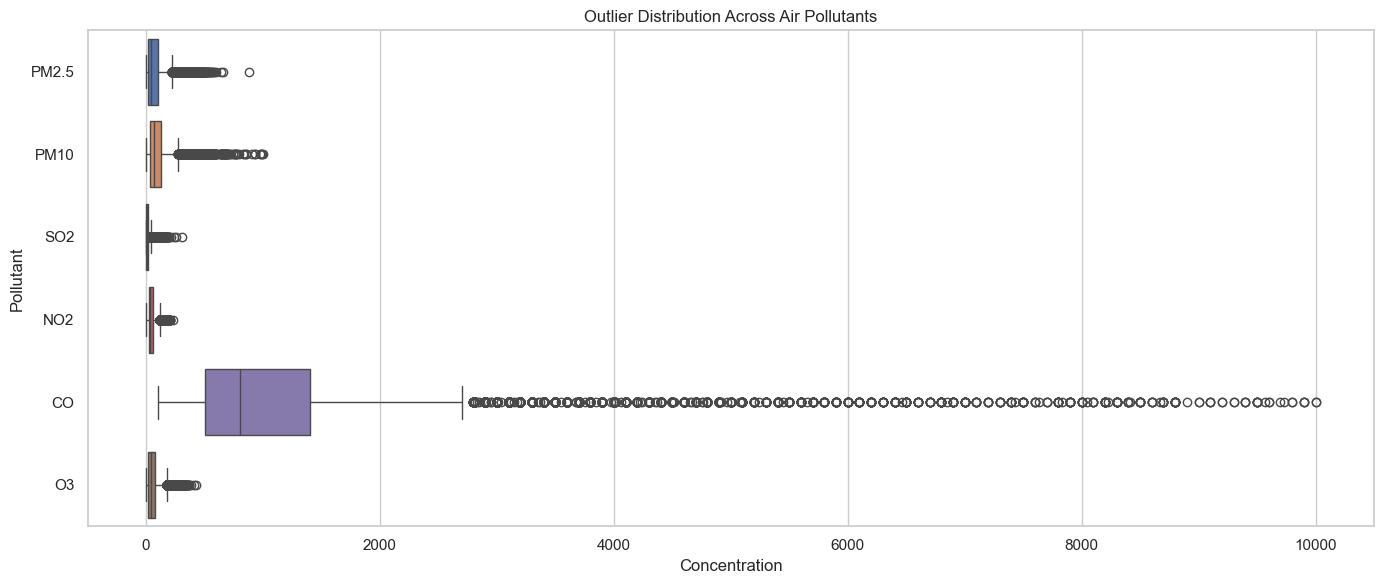

In [6]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_clean[outlier_cols],
    orient="h"
)

plt.title("Outlier Distribution Across Air Pollutants")
plt.xlabel("Concentration")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis (EDA)

### EDA 1 - Statistik deskriptif dan tren waktu

In [7]:
print("Statistik PM2.5:")
display(df_clean["PM2.5"].describe())

monthly_pm25 = (
    df_clean.set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
)

print("Bulan dengan rata-rata PM2.5 tertinggi:")
display(monthly_pm25.nlargest(5))

print("Bulan dengan rata-rata PM2.5 terendah:")
display(monthly_pm25.nsmallest(5))

Statistik PM2.5:


count   34632.00
mean       71.15
std        72.48
min         2.00
25%        18.00
50%        46.00
75%       100.00
max       882.00
Name: PM2.5, dtype: float64

Bulan dengan rata-rata PM2.5 tertinggi:


datetime
2014-02-01   140.81
2015-12-01   120.31
2014-10-01   117.34
2016-12-01   109.82
2014-04-01   104.50
Name: PM2.5, dtype: float64

Bulan dengan rata-rata PM2.5 terendah:


datetime
2016-08-01   36.67
2016-02-01   38.42
2015-08-01   38.53
2015-09-01   43.03
2016-09-01   44.80
Name: PM2.5, dtype: float64

**Insight:** 
- Rata-rata konsentrasi PM2.5: Konsentrasi PM2.5 memiliki rata-rata sebesar 71,15, median 46, nilai minimum 2, dan maksimum 882. Rata-rata yang lebih tinggi daripada median menunjukkan distribusi yang cenderung menceng ke kanan (right-skewed), dengan sejumlah observasi berkonsentrasi tinggi.

- Bulan dengan rata-rata PM2.5 tertinggi: Februari 2014, dengan rata-rata 140,81, diikuti Desember 2015 sebesar 120,31 dan Oktober 2014 sebesar 117,34.

- Bulan dengan rata-rata PM2.5 terendah: Agustus 2016, dengan rata-rata 36,67, diikuti Februari 2016 sebesar 38,42 dan Agustus 2015 sebesar 38,53.

- Pola temporal: Hasil tersebut menunjukkan variasi konsentrasi PM2.5 antarbulan. Bulan-bulan dengan rata-rata tinggi dan rendah dapat digunakan sebagai dasar untuk mengeksplorasi pola musiman, tetapi belum cukup untuk menyimpulkan tren jangka panjang atau penyebab perubahan polusi.

### EDA 2 - Hubungan antarvariabel

In [8]:
pollution_weather_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

corr = df_clean[pollution_weather_cols].corr(
    method="spearman",
    numeric_only=True
)

display(corr["PM2.5"].sort_values(ascending=False))

PM2.5    1.00
PM10     0.88
CO       0.82
NO2      0.64
SO2      0.43
DEWP     0.22
RAIN    -0.00
TEMP    -0.04
PRES    -0.06
O3      -0.22
WSPM    -0.33
Name: PM2.5, dtype: float64

**Insight:** 
- Hubungan positif terkuat: PM10 memiliki korelasi Spearman sebesar 0,88 dengan PM2.5, diikuti CO sebesar 0,82 dan NO2 sebesar 0,64. Hal ini menunjukkan bahwa konsentrasi PM2.5 cenderung meningkat ketika nilai variabel tersebut meningkat.

- Hubungan positif sedang: SO2 memiliki korelasi 0,43, sedangkan DEWP memiliki korelasi 0,22 dengan PM2.5.

- Hubungan negatif: Kecepatan angin (WSPM) memiliki korelasi negatif sebesar −0,33, diikuti O3 sebesar −0,22. Suhu (TEMP) dan tekanan udara (PRES) memiliki korelasi negatif yang relatif lemah, masing-masing −0,04 dan −0,06.

- Hubungan yang sangat lemah: Curah hujan (RAIN) memiliki korelasi yang mendekati nol pada hasil yang ditampilkan.

- Implikasi analisis: PM10, CO, dan NO2 merupakan variabel yang paling kuat berhubungan secara monotonik dengan PM2.5 dalam analisis ini. Kecepatan angin juga layak diperiksa lebih lanjut untuk memahami pola dispersi polutan. Korelasi ini tidak membuktikan hubungan sebab-akibat.

## Visualization & Explanatory Analysis

Bagian ini menyajikan visualisasi dan analisis eksploratif untuk menjawab pertanyaan bisnis yang telah dirumuskan sebelumnya. Visualisasi digunakan untuk mengidentifikasi pola temporal konsentrasi PM2.5 serta mengeksplorasi hubungan antara PM2.5 dengan variabel meteorologi dan polutan lainnya di stasiun pemantauan Changping selama periode Maret 2013 hingga Februari 2017.

### Pertanyaan 1

**Bagaimana pola perubahan rata-rata konsentrasi PM2.5 berdasarkan jam dan bulan selama periode Maret 2013 hingga Februari 2017?**

Analisis ini dilakukan untuk mengidentifikasi pola temporal dan variasi konsentrasi PM2.5 berdasarkan waktu pengamatan. Visualisasi yang digunakan meliputi:

- **Grafik tren rata-rata konsentrasi PM2.5 bulanan**, untuk mengamati perubahan konsentrasi PM2.5 dari bulan ke bulan selama periode pengamatan.
- **Grafik rata-rata konsentrasi PM2.5 berdasarkan jam**, untuk mengidentifikasi pola variasi konsentrasi PM2.5 selama 24 jam.
- **Heatmap rata-rata konsentrasi PM2.5 berdasarkan kombinasi bulan dan jam**, untuk mengeksplorasi distribusi konsentrasi PM2.5 pada setiap kombinasi waktu.

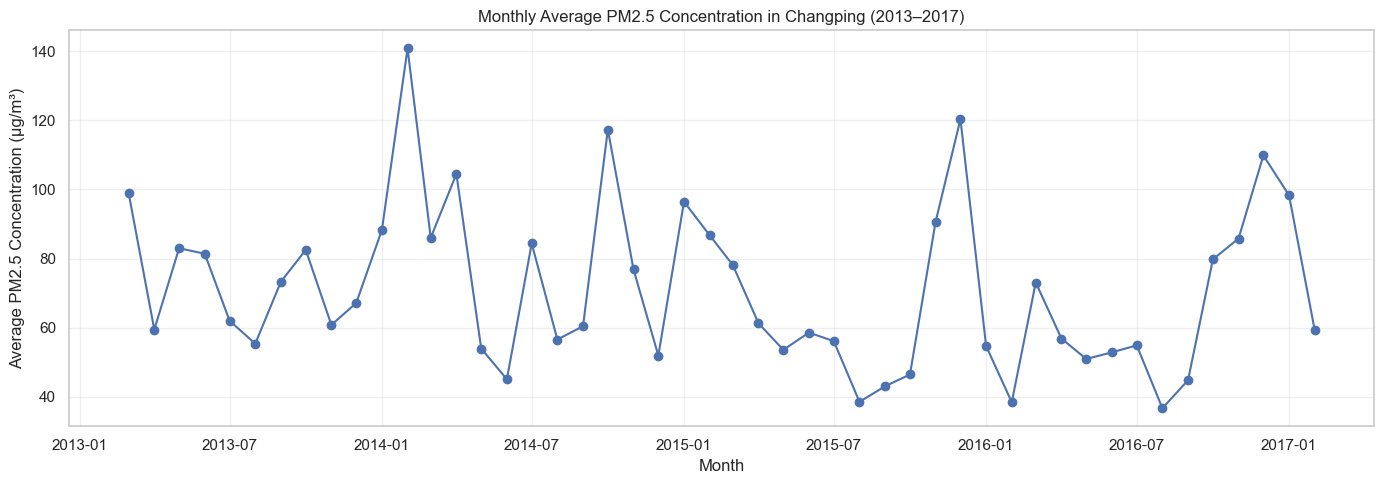

In [9]:
monthly_pm25 = (
    df_clean.set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    marker="o",
    linewidth=1.5
)

plt.title(
    "Monthly Average PM2.5 Concentration in Changping (2013–2017)"
)
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insight: Tren Konsentrasi PM2.5 Bulanan di Changping (2013–2017)

Berdasarkan grafik rata-rata konsentrasi PM2.5 bulanan selama periode Maret 2013 hingga Februari 2017, diperoleh beberapa temuan utama:

1. **Fluktuasi konsentrasi PM2.5:** Konsentrasi PM2.5 menunjukkan fluktuasi yang cukup besar dari bulan ke bulan. Tidak terlihat pola peningkatan atau penurunan yang konsisten sepanjang periode pengamatan.

2. **Periode dengan konsentrasi tertinggi:** Rata-rata konsentrasi PM2.5 tertinggi terjadi pada Februari 2014, yaitu sekitar **140,81 µg/m³**. Konsentrasi yang relatif tinggi juga terlihat pada Desember 2015 (120,31 µg/m³), Oktober 2014 (117,34 µg/m³), dan November 2016 (109,82 µg/m³).

3. **Periode dengan konsentrasi terendah:** Rata-rata konsentrasi PM2.5 terendah tercatat pada Agustus 2016, yaitu sekitar **36,67 µg/m³**. Nilai yang relatif rendah juga ditemukan pada Februari 2016 (38,42 µg/m³) dan Agustus 2015 (38,53 µg/m³).

4. **Variasi temporal dan indikasi musiman:** Grafik menunjukkan adanya variasi konsentrasi PM2.5 yang cukup besar sepanjang periode pengamatan. Beberapa lonjakan konsentrasi terlihat pada bulan-bulan tertentu, tetapi pola musiman yang konsisten belum dapat dipastikan hanya berdasarkan tren bulanan. Oleh karena itu, diperlukan analisis tambahan berdasarkan jam pengamatan dan kombinasi bulan serta jam untuk memahami pola temporal secara lebih mendalam.

**Kesimpulan sementara:** Konsentrasi PM2.5 di Changping mengalami variasi temporal yang cukup besar selama periode Maret 2013 hingga Februari 2017. Februari 2014 merupakan bulan dengan rata-rata konsentrasi tertinggi, sedangkan Agustus 2016 merupakan bulan dengan rata-rata terendah. Temuan ini menunjukkan pentingnya analisis temporal lebih lanjut untuk mengidentifikasi periode dengan konsentrasi PM2.5 relatif tinggi maupun rendah.

### Pertanyaan 2

**Bagaimana arah dan kekuatan hubungan antara konsentrasi PM2.5 dan variabel meteorologi, meliputi suhu, tekanan udara, curah hujan, kelembapan titik embun, serta kecepatan angin, selama periode Maret 2013 hingga Februari 2017?**

Analisis ini dilakukan untuk mengeksplorasi hubungan antara konsentrasi PM2.5 dan variabel meteorologi selama periode pengamatan. Pengukuran hubungan antarvariabel menggunakan **korelasi Spearman** karena metode ini mengukur kekuatan dan arah hubungan monotonik antarvariabel.

Variabel meteorologi yang dianalisis meliputi:

- **TEMP:** Rata-rata suhu udara.
- **PRES:** Tekanan udara.
- **RAIN:** Curah hujan.
- **DEWP:** Suhu titik embun (*dew point*).
- **WSPM:** Kecepatan angin.

Hasil analisis disajikan melalui visualisasi korelasi untuk mengidentifikasi arah dan kekuatan hubungan setiap variabel meteorologi dengan konsentrasi PM2.5.

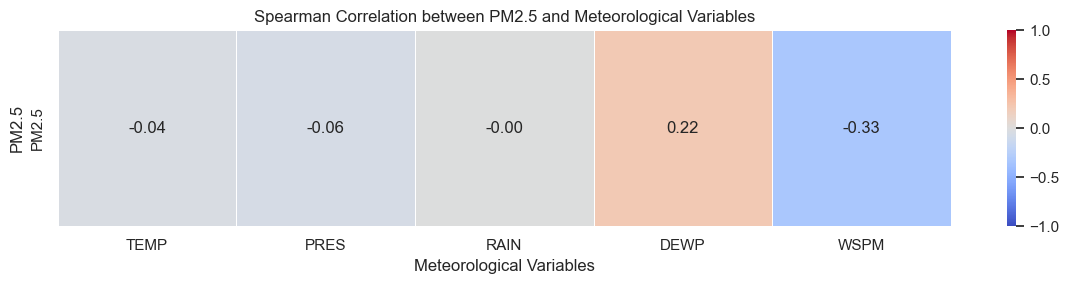

In [10]:
meteorological_vars = [
    "TEMP", "PRES", "RAIN", "DEWP", "WSPM"
]

corr_meteorology = (
    df_clean[["PM2.5"] + meteorological_vars]
    .corr(method="spearman")
    .loc[["PM2.5"], meteorological_vars]
)

plt.figure(figsize=(12, 3))

sns.heatmap(
    corr_meteorology,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Spearman Correlation between PM2.5 and Meteorological Variables")
plt.xlabel("Meteorological Variables")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

### Insight: Hubungan PM2.5 dengan Variabel Meteorologi

Berdasarkan heatmap korelasi Spearman, diperoleh beberapa temuan mengenai hubungan antara konsentrasi PM2.5 dan variabel meteorologi selama periode Maret 2013 hingga Februari 2017:

1. **DEWP (Dew Point):** Memiliki korelasi positif sebesar 0,22. Hal ini menunjukkan bahwa peningkatan suhu titik embun cenderung berkaitan dengan peningkatan konsentrasi PM2.5, meskipun hubungan tersebut tergolong lemah.

2. **WSPM (Wind Speed):** Memiliki korelasi negatif sebesar -0,33 dan merupakan variabel meteorologi dengan hubungan negatif paling kuat terhadap PM2.5. Hasil ini mengindikasikan bahwa peningkatan kecepatan angin cenderung berkaitan dengan penurunan konsentrasi PM2.5.

3. **TEMP (Temperature) dan PRES (Air Pressure):** Masing-masing memiliki korelasi negatif sebesar -0,04 dan -0,06. Nilai tersebut menunjukkan hubungan monotonik yang sangat lemah dengan konsentrasi PM2.5.

4. **RAIN (Rainfall):** Memiliki koefisien korelasi yang mendekati nol (-0,00), sehingga tidak menunjukkan hubungan monotonik yang berarti dengan konsentrasi PM2.5 dalam analisis ini.

**Kesimpulan:** Di antara lima variabel meteorologi yang dianalisis, WSPM memiliki hubungan negatif paling kuat dengan konsentrasi PM2.5, sedangkan DEWP menunjukkan hubungan positif. Meskipun demikian, seluruh koefisien korelasi relatif kecil sehingga hubungan antara variabel meteorologi dan PM2.5 secara umum tergolong lemah. Temuan ini menunjukkan bahwa variasi konsentrasi PM2.5 tidak dapat dijelaskan hanya berdasarkan hubungan monotonik dengan satu variabel meteorologi.

Perlu diperhatikan bahwa korelasi Spearman menunjukkan arah dan kekuatan hubungan monotonik, bukan hubungan sebab-akibat. Oleh karena itu, hasil ini tidak dapat langsung digunakan untuk menyimpulkan pengaruh kausal variabel meteorologi terhadap konsentrasi PM2.5.

### Pertanyaan 3

**Polutan apa yang memiliki hubungan paling kuat dengan konsentrasi PM2.5 berdasarkan koefisien korelasi Spearman selama periode Maret 2013 hingga Februari 2017?**

Analisis ini dilakukan untuk mengeksplorasi hubungan antara konsentrasi PM2.5 dan polutan lainnya selama periode pengamatan. Pengukuran hubungan antarvariabel menggunakan **korelasi Spearman** untuk mengetahui arah dan kekuatan hubungan monotonik antara konsentrasi PM2.5 dan masing-masing polutan.

Polutan yang dianalisis meliputi:

- **PM10:** Particulate Matter dengan diameter aerodinamis hingga 10 mikrometer.
- **SO2:** Sulfur Dioxide.
- **NO2:** Nitrogen Dioxide.
- **CO:** Carbon Monoxide.
- **O3:** Ozone.

Hasil analisis disajikan melalui visualisasi korelasi untuk mengidentifikasi polutan yang memiliki hubungan paling kuat dengan konsentrasi PM2.5.

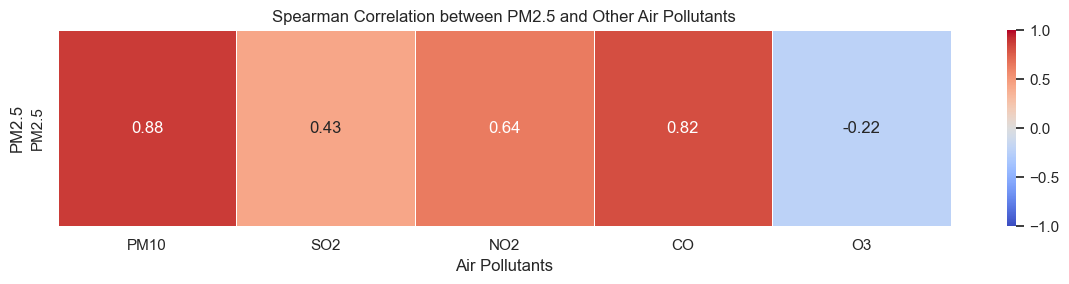

In [11]:
pollutant_vars = ["PM10", "SO2", "NO2", "CO", "O3"]

corr_pollutants = (
    df_clean[["PM2.5"] + pollutant_vars]
    .corr(method="spearman")
    .loc[["PM2.5"], pollutant_vars]
)

plt.figure(figsize=(12, 3))

sns.heatmap(
    corr_pollutants,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Spearman Correlation between PM2.5 and Other Air Pollutants")
plt.xlabel("Air Pollutants")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

### Insight: Hubungan PM2.5 dengan Polutan Lainnya

Berdasarkan heatmap korelasi Spearman selama periode Maret 2013 hingga Februari 2017, diperoleh beberapa temuan utama:

1. **PM10:** Memiliki korelasi positif sangat kuat sebesar 0,88. Hal ini menunjukkan bahwa peningkatan konsentrasi PM10 cenderung berkaitan dengan peningkatan konsentrasi PM2.5. PM10 merupakan polutan dengan hubungan paling kuat terhadap PM2.5 di antara variabel yang dianalisis.

2. **CO:** Menunjukkan korelasi positif sangat kuat sebesar 0,82. Hasil ini mengindikasikan adanya hubungan monotonik positif yang kuat antara konsentrasi CO dan PM2.5.

3. **NO2:** Memiliki korelasi positif kuat sebesar 0,64. Peningkatan konsentrasi NO2 cenderung berkaitan dengan peningkatan konsentrasi PM2.5.

4. **SO2:** Menunjukkan korelasi positif sedang sebesar 0,43, yang mengindikasikan adanya hubungan positif antara konsentrasi SO2 dan PM2.5.

5. **O3:** Memiliki korelasi negatif lemah sebesar -0,22. Hal ini menunjukkan bahwa peningkatan konsentrasi O3 cenderung berkaitan dengan penurunan konsentrasi PM2.5, meskipun hubungannya relatif lemah.

**Kesimpulan:** PM10 merupakan polutan yang memiliki hubungan paling kuat dengan konsentrasi PM2.5, dengan koefisien korelasi Spearman sebesar 0,88, diikuti oleh CO (0,82) dan NO2 (0,64). Hasil ini menunjukkan adanya keterkaitan yang kuat antara konsentrasi PM2.5 dengan beberapa polutan lainnya, terutama PM10 dan CO.

Perlu diperhatikan bahwa korelasi menunjukkan arah dan kekuatan hubungan monotonik, bukan hubungan sebab-akibat. Oleh karena itu, hasil ini tidak dapat digunakan secara langsung untuk menyimpulkan bahwa peningkatan suatu polutan menyebabkan peningkatan PM2.5.

## Analisis Lanjutan (Opsional)

### Tujuan Analisis

Analisis lanjutan dilakukan untuk memperoleh pemahaman yang lebih mendalam mengenai pola distribusi konsentrasi PM2.5 berdasarkan dimensi waktu. Analisis ini bertujuan mengidentifikasi variasi konsentrasi polutan yang mungkin belum terlihat melalui analisis deskriptif dan korelasi sebelumnya.

Analisis lanjutan mencakup beberapa pendekatan berikut:

1. **Hourly PM2.5 Analysis**

   Mengidentifikasi perubahan rata-rata konsentrasi PM2.5 berdasarkan jam pengamatan selama 24 jam untuk mengetahui periode ketika tingkat polusi cenderung meningkat atau menurun.

2. **Hourly and Monthly PM2.5 Analysis**

   Menganalisis distribusi konsentrasi PM2.5 berdasarkan kombinasi jam dan bulan untuk mengidentifikasi periode dengan tingkat polusi relatif tinggi maupun rendah serta mengeksplorasi kemungkinan variasi musiman.

3. **Weekday vs Weekend Analysis**

   Membandingkan distribusi konsentrasi PM2.5 antara hari kerja (*weekday*) dan akhir pekan (*weekend*) untuk mengetahui kemungkinan perbedaan karakteristik tingkat polusi berdasarkan jenis hari.

### Manfaat Analisis Lanjutan

- Mengidentifikasi periode waktu yang berpotensi memiliki konsentrasi PM2.5 tinggi.
- Memahami variasi konsentrasi PM2.5 berdasarkan pola harian dan bulanan.
- Mengeksplorasi kemungkinan perbedaan tingkat polusi antara hari kerja dan akhir pekan.
- Memberikan informasi tambahan sebagai dasar rekomendasi pemantauan dan pengendalian kualitas udara.

Analisis ini menggunakan pendekatan eksploratif dan deskriptif tanpa menerapkan algoritma Machine Learning. Hasil yang diperoleh digunakan untuk memperluas interpretasi terhadap karakteristik kualitas udara di Changping selama periode pengamatan 2013–2017.

### Analisis rata-rata PM2.5 berdasarkan jam

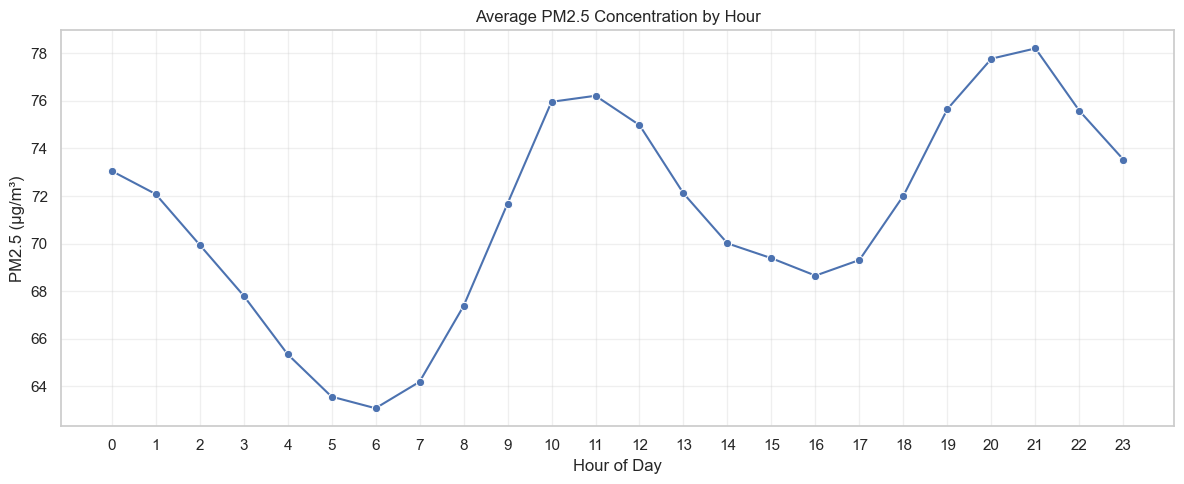

In [12]:
hourly_pm25 = (
    df_clean.groupby("hour")["PM2.5"]
    .mean()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_pm25.index,
    y=hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insight: Diurnal Variation of PM2.5 Concentration

Berdasarkan analisis rata-rata konsentrasi PM2.5 berdasarkan jam, terlihat adanya variasi konsentrasi polutan sepanjang hari.

- **Lowest concentration:** Konsentrasi PM2.5 terendah terjadi pada pukul 06.00, dengan nilai sekitar 63,1 µg/m³.
- **Morning increase:** Konsentrasi mulai meningkat setelah pukul 07.00 dan mencapai sekitar 76 µg/m³ pada pukul 10.00–12.00.
- **Afternoon decline:** Konsentrasi mengalami penurunan setelah pukul 12.00 dan mencapai sekitar 68,7 µg/m³ pada pukul 16.00.
- **Evening peak:** Peningkatan kembali terjadi pada malam hari, dengan konsentrasi tertinggi sekitar 78,2 µg/m³ pada pukul 21.00.

Secara keseluruhan, konsentrasi PM2.5 menunjukkan dua periode peningkatan utama, yaitu menjelang siang dan malam hari. Temuan ini memperlihatkan bahwa tingkat polusi udara di Changping memiliki variasi temporal berdasarkan waktu pengamatan. Analisis lebih lanjut terhadap variabel meteorologi diperlukan untuk memahami faktor-faktor yang berkaitan dengan pola tersebut.

### Analisis pola PM2.5 berdasarkan bulan dan jam

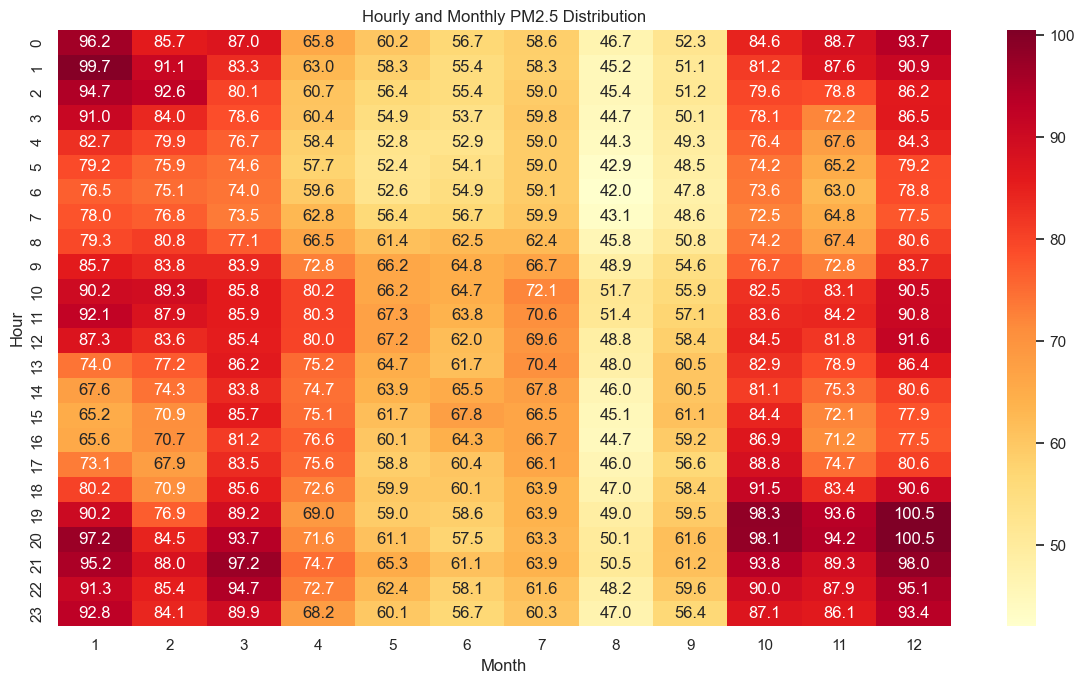

In [13]:
hour_month = df_clean.pivot_table(
    index="hour",
    columns="month",
    values="PM2.5",
    aggfunc="mean"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    hour_month,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f"
)

plt.title("Hourly and Monthly PM2.5 Distribution")
plt.xlabel("Month")
plt.ylabel("Hour")
plt.tight_layout()
plt.show()

### Insight: Hourly and Monthly PM2.5 Distribution

Berdasarkan heatmap distribusi konsentrasi PM2.5 berdasarkan jam dan bulan, terlihat adanya variasi temporal yang cukup jelas selama periode pengamatan.

- **Monthly variation:** Konsentrasi PM2.5 relatif tinggi pada Januari–Maret dan Oktober–Desember, sedangkan April–September cenderung menunjukkan konsentrasi yang lebih rendah.
- **Highest concentration:** Nilai tertinggi tercatat pada Desember pukul 19.00–20.00, yaitu sekitar 100,5 µg/m³.
- **Lowest concentration:** Nilai terendah ditemukan pada Agustus pukul 06.00, yaitu sekitar 42,0 µg/m³.
- **Hourly variation:** Konsentrasi PM2.5 cenderung meningkat pada malam hari, khususnya pukul 19.00–21.00, meskipun pola tersebut bervariasi antarbulan.
- **Seasonal variation:** Perbedaan distribusi konsentrasi antara April–September dan Oktober–Maret menunjukkan kemungkinan adanya variasi musiman dalam tingkat polusi udara.

Secara keseluruhan, hasil visualisasi menunjukkan bahwa konsentrasi PM2.5 dipengaruhi oleh variasi waktu pengamatan, baik berdasarkan jam maupun bulan. Analisis lebih lanjut terhadap variabel meteorologi diperlukan untuk mengeksplorasi faktor-faktor yang berkaitan dengan pola tersebut.

### Analisis weekday vs weekend

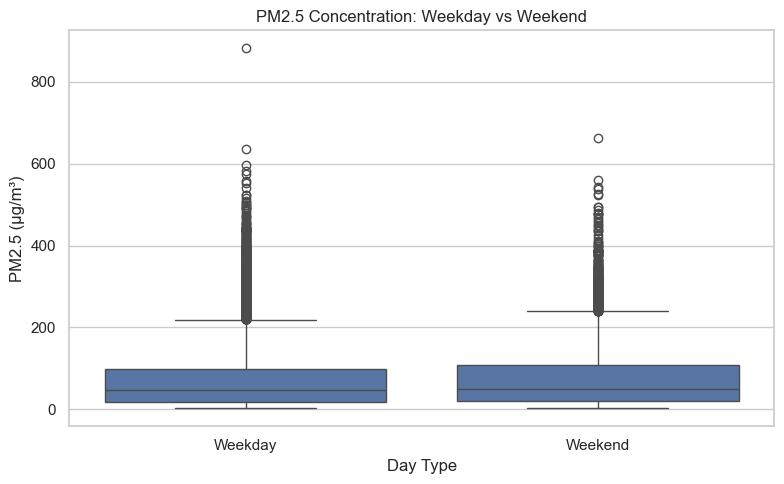

In [14]:
df_clean["day_type"] = (
    df_clean["datetime"]
    .dt.dayofweek
    .apply(lambda x: "Weekend" if x >= 5 else "Weekday")
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="day_type",
    y="PM2.5"
)

plt.title("PM2.5 Concentration: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

### Insight: PM2.5 Concentration on Weekdays vs Weekends

Berdasarkan visualisasi boxplot, distribusi konsentrasi PM2.5 pada hari kerja (weekday) dan akhir pekan (weekend) menunjukkan karakteristik yang relatif serupa.

- **Median concentration:** Median PM2.5 pada akhir pekan sedikit lebih tinggi dibandingkan hari kerja, yaitu sekitar 48 µg/m³ dan 45 µg/m³.
- **Data distribution:** Kedua kelompok memiliki rentang interkuartil yang cukup lebar, menunjukkan adanya variasi konsentrasi PM2.5 dalam masing-masing kelompok.
- **Outliers:** Kedua kelompok memiliki banyak pencilan pada konsentrasi tinggi. Nilai ekstrem pada hari kerja mencapai sekitar 880 µg/m³, sedangkan pada akhir pekan mencapai sekitar 660 µg/m³.
- **Distribution pattern:** Kedua kelompok menunjukkan distribusi yang menceng ke kanan (right-skewed), yang mengindikasikan adanya sejumlah pengamatan dengan konsentrasi PM2.5 jauh lebih tinggi dibandingkan sebagian besar pengamatan lainnya.

Secara keseluruhan, konsentrasi PM2.5 pada hari kerja dan akhir pekan memiliki distribusi yang relatif serupa, meskipun terdapat sedikit perbedaan pada nilai median dan pencilan ekstrem. Pengujian statistik lebih lanjut diperlukan untuk menentukan apakah perbedaan konsentrasi antara kedua kelompok tersebut signifikan secara statistik.

In [15]:
from scipy.stats import mannwhitneyu

weekday = df_clean.loc[
    df_clean["day_type"] == "Weekday", "PM2.5"
].dropna()

weekend = df_clean.loc[
    df_clean["day_type"] == "Weekend", "PM2.5"
].dropna()

stat, p_value = mannwhitneyu(
    weekday,
    weekend,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Terdapat perbedaan distribusi yang signifikan.")
else:
    print("Tidak ditemukan perbedaan distribusi yang signifikan.")

Mann-Whitney U Statistic: 117588038.5
P-value: 2.541070209780366e-08
Terdapat perbedaan distribusi yang signifikan.


# Conclusion & Recommendation

## Kesimpulan

### Pertanyaan 1: Bagaimana pola perubahan rata-rata konsentrasi PM2.5 berdasarkan jam dan bulan selama periode Maret 2013 hingga Februari 2017?

- Rata-rata konsentrasi PM2.5 selama periode pengamatan adalah sekitar **71,15 µg/m³**, dengan standar deviasi **72,48 µg/m³**.
- Rata-rata konsentrasi bulanan tertinggi terjadi pada **Februari 2014**, yaitu sebesar **140,81 µg/m³**, sedangkan terendah terjadi pada **Agustus 2016**, sebesar **36,67 µg/m³**.
- Konsentrasi PM2.5 menunjukkan fluktuasi yang cukup besar dari bulan ke bulan tanpa pola peningkatan atau penurunan jangka panjang yang konsisten.
- Analisis temporal berdasarkan jam menunjukkan adanya variasi konsentrasi selama 24 jam, dengan periode peningkatan yang terlihat pada malam hari.

### Pertanyaan 2: Bagaimana arah dan kekuatan hubungan antara konsentrasi PM2.5 dan variabel meteorologi selama periode Maret 2013 hingga Februari 2017?

- WSPM (kecepatan angin) menunjukkan hubungan negatif paling kuat dengan PM2.5 di antara variabel meteorologi yang dianalisis, dengan koefisien Spearman sebesar **-0,33**.
- DEWP (suhu titik embun) menunjukkan hubungan positif dengan PM2.5 sebesar **0,22**.
- TEMP (suhu udara) dan PRES (tekanan udara) menunjukkan hubungan negatif yang sangat lemah, masing-masing sebesar **-0,04** dan **-0,06**.
- RAIN (curah hujan) memiliki koefisien korelasi yang mendekati nol.
- Secara keseluruhan, hubungan antara variabel meteorologi dan PM2.5 relatif lemah berdasarkan korelasi Spearman.

### Pertanyaan 3: Polutan apa yang memiliki hubungan paling kuat dengan konsentrasi PM2.5 berdasarkan koefisien korelasi Spearman selama periode Maret 2013 hingga Februari 2017?

- PM10 memiliki hubungan positif paling kuat dengan PM2.5, dengan koefisien Spearman sebesar **0,88**.
- CO menunjukkan hubungan positif sangat kuat sebesar **0,82**, diikuti NO2 sebesar **0,64**.
- SO2 memiliki hubungan positif sedang sebesar **0,43**, sedangkan O3 menunjukkan hubungan negatif lemah sebesar **-0,22**.
- Hasil tersebut menunjukkan bahwa PM10 dan CO merupakan polutan yang memiliki hubungan paling kuat dengan konsentrasi PM2.5 di antara polutan yang dianalisis.

### Analisis Tambahan

- Distribusi konsentrasi PM2.5 pada weekday dan weekend relatif serupa, meskipun median weekend sedikit lebih tinggi.
- Kedua kelompok memiliki sejumlah nilai ekstrem (*outliers*), yang menunjukkan adanya periode dengan konsentrasi PM2.5 yang tinggi.

## Rekomendasi (Action Items)

1. **Meningkatkan pemantauan kualitas udara:** Memprioritaskan pemantauan PM2.5 dan PM10 secara berkala, khususnya pada periode yang berdasarkan analisis historis menunjukkan konsentrasi relatif tinggi.

2. **Memperhatikan variasi temporal:** Mengoptimalkan pemantauan kualitas udara berdasarkan variasi jam dan bulan untuk mengidentifikasi periode dengan konsentrasi PM2.5 yang cenderung meningkat.

3. **Mengintegrasikan informasi antarpolutan:** Mempertimbangkan PM10, CO, dan NO2 sebagai variabel pendukung dalam analisis kualitas udara karena memiliki hubungan positif yang kuat dengan PM2.5.

4. **Mempertimbangkan kondisi meteorologi:** Memasukkan informasi kecepatan angin dan suhu titik embun dalam analisis lanjutan untuk mengeksplorasi keterkaitannya dengan variasi konsentrasi PM2.5.

5. **Mengembangkan analisis lanjutan:** Melakukan penelitian lebih lanjut menggunakan data dengan cakupan waktu dan variabel yang lebih luas untuk mengeksplorasi faktor-faktor yang berkaitan dengan konsentrasi PM2.5 serta mendukung pengembangan sistem pemantauan kualitas udara.

In [16]:
df_clean.to_csv("air_quality_changping_clean.csv", index=False)